## Подробное исследование признаков

В данном ноутбуке представлена история исследования данных и введение правил обработки.



In [2]:
import sys
import os
sys.path.append(os.path.abspath('..'))

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from src.utils import evaluate_preds, show_weights
import seaborn as sns

df = pd.read_csv('../data/raw/train.csv')

Рассмотрим признак `Square`. 1% квартиль = 29.72 (далее для краткости буду обозначать Q_1) и 99% квартиль = 117.86 (Q_99 соответственно). Все значения не входящие в интервал [Q_1, Q_99] буду считать аномальными, требующие рассмотрения

In [4]:
square_q1, square_q99 = df['Square'].quantile(0.01), df['Square'].quantile(0.99)
square_q1_less_mask = df['Square'] < square_q1
square_q1_greater_mask = df['Square'] >= square_q1
square_q99_greater_mask = df['Square'] > square_q99
square_q99_less_mask = df['Square'] <= square_q99

square_q1_q99_outside_mask = square_q1_less_mask | square_q99_greater_mask
square_q1_q99_inside_mask = square_q1_greater_mask & square_q99_less_mask

df[square_q1_q99_outside_mask]

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
111,13875,20,1.0,28.438794,32.514021,6.0,6,10.0,2014,0.019509,B,B,37,7687,11,176.0,5,5,B,199248.114376
130,8800,23,1.0,29.706031,NaN,0.0,5,12.0,1977,0.034656,B,B,0,168,0,NaN,0,0,B,60502.583500
136,5284,27,4.0,119.914990,78.518874,13.0,8,12.0,2015,0.072158,B,B,2,629,1,NaN,0,0,A,221374.057293
161,6782,45,1.0,2.954309,5.257278,1.0,3,1.0,1977,0.195781,B,B,23,5212,6,NaN,3,2,B,438005.182323
234,4935,23,1.0,28.859885,NaN,1.0,12,11.0,1977,0.034656,B,B,0,168,0,NaN,0,0,B,68375.615508
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9846,1205,23,2.0,148.671938,100.201652,1.0,1,3.0,2013,0.014073,B,B,2,475,0,NaN,0,0,B,152464.848743
9869,3224,27,0.0,2.377248,0.873147,0.0,1,0.0,1977,0.017647,B,B,2,469,0,NaN,0,0,B,126596.941798
9877,11391,62,3.0,122.181937,NaN,1.0,3,3.0,1977,0.072158,B,B,2,629,1,NaN,0,0,A,259991.137225
9990,10635,21,1.0,18.983962,11.419796,2.0,1,5.0,1967,0.194489,B,B,47,8004,3,125.0,3,5,B,112411.221700


## написать описание логики, расставить флаги потом


In [ ]:
# Rooms = 0 and Square < Q_1
df.loc[(df['Rooms'] == 0) & (df['Square'] < square_q1), ['KitchenSquare','LifeSquare']] = [0, 0]

# Q_1 < Rooms < Q_99 and Square < Q_1
rooms_q1, rooms_q99 = df['Rooms'].quantile(0.01), df['Rooms'].quantile(0.99)
rooms_q1_less_mask     = df['Rooms'] < rooms_q1
rooms_q1_greater_mask  = df['Rooms'] >= rooms_q1
rooms_q99_greater_mask = df['Rooms'] > rooms_q99
rooms_q99_less_mask    = df['Rooms'] <= rooms_q99
rooms_q1_q99_inside_mask  = rooms_q1_greater_mask & rooms_q99_less_mask
rooms_q1_q99_outside_mask = rooms_q1_less_mask | rooms_q99_greater_mask

median_square_per_room_ = (
    df.loc[square_q1_q99_inside_mask & rooms_q1_q99_inside_mask, 'Square']
    / df.loc[square_q1_q99_inside_mask & rooms_q1_q99_inside_mask, 'Rooms']
).median()


# клип к нижней границе (только для слишком маленьких Square при Rooms>=1).
df.loc[(rooms_q1_q99_inside_mask) & (square_q1_less_mask), 'Square'] = (
    median_square_per_room_ * df.loc[(rooms_q1_q99_inside_mask) & (square_q1_less_mask), 'Rooms']
).clip(lower=square_q1)

# Пустые объекты
indices_to_drop = df[(df['Rooms'] == 0) & (df['Square'] == 0) & (df['LifeSquare'] == 0) & (df['KitchenSquare'] == 0)].index
df.drop(index=indices_to_drop, inplace=True)

# Клип к верхней границе (только для слишком больших Square при Rooms>=1).
df['Square_per_room'] = df['Square'] / df['Rooms']
square_per_room_greater_median_mask = df['Square_per_room'] > (5 * median_square_per_room_)
square_per_room_less_median_mask    = df['Square_per_room'] < (median_square_per_room_ / 5)


upper_cap = df['Rooms'] * median_square_per_room_ * 5
lower_cap = df['Rooms'] * median_square_per_room_ / 5

mask_hi = square_q99_greater_mask & square_per_room_greater_median_mask & rooms_q1_greater_mask
mask_lo = square_q99_greater_mask & square_per_room_less_median_mask    & rooms_q1_greater_mask

df.loc[mask_hi, 'Square'] = np.minimum(df.loc[mask_hi, 'Square'], upper_cap.loc[mask_hi])
df.loc[mask_lo, 'Square'] = np.maximum(df.loc[mask_lo, 'Square'], lower_cap.loc[mask_lo])
df.drop('Square_per_room', axis=1, inplace=True)

Рассмотреним признак `Rooms`. Он имеет максимальное значение = 19 и минимальное = 0 (при Q_99 = 4 и Q_1 = 1)

Применим ограничение `Rooms [1, 7]`, как диапозон наиболее возможных значений



In [6]:
display(df[rooms_q1_q99_outside_mask])
df.loc[rooms_q1_q99_outside_mask, 'Rooms'] = df.loc[rooms_q1_q99_outside_mask, 'Rooms'].clip(lower=1, upper=7)

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Ecology_2,Ecology_3,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Shops_2,Price
403,13434,13,5.0,183.382273,100.985505,15.0,2,6.0,1997,0.090799,B,B,74,19083,2,NaN,5,15,B,622888.825328
505,3454,8,5.0,112.135525,79.795451,10.0,4,17.0,1999,0.437885,B,B,23,5735,3,1084.0,0,5,B,471833.787538
511,8685,62,5.0,124.933289,81.122369,30.0,5,3.0,2017,0.072158,B,B,2,629,1,NaN,0,0,A,271919.866048
940,4971,169,5.0,117.855969,76.561318,9.0,12,14.0,2001,0.178917,B,B,18,3594,4,192.0,1,5,B,608674.130507
1459,8901,34,5.0,121.577423,114.913843,1.0,25,1.0,1977,0.069753,B,B,53,13670,4,NaN,1,11,B,455446.393758
1906,5548,86,5.0,275.645284,233.949309,26.0,12,37.0,2011,0.161976,B,A,31,7010,5,4508.0,3,7,B,455264.882666
1909,238,88,5.0,90.762276,70.991790,5.0,1,9.0,1972,0.127376,B,B,43,8429,3,NaN,3,9,B,289683.939174
2004,5927,57,10.0,59.056975,36.223072,10.0,22,22.0,2002,0.090799,B,B,74,19083,2,NaN,5,15,B,317265.323792
2194,3159,88,0.0,38.697117,19.345131,9.0,9,16.0,1982,0.127376,B,B,43,8429,3,NaN,3,9,B,158998.110646
2516,338,46,5.0,147.709302,NaN,0.0,6,0.0,1977,0.150818,B,B,16,3433,4,2643.0,4,5,B,352168.955975


Рассмотрим разные способы заполнения пропущенных значений признака `LifeSquare`:
1. Заполненение медианой
2. Заполнение по правилу `Square ~= KitchenSquare + LifeSquare`
3. Заполнение при помощи моделей (линейная регрессия, KNN)

In [7]:
lifesquare_greater_square_mask = ((df['LifeSquare'] - df['Square']) < (df['Square'])) & ((df['LifeSquare'] - df['Square']) > 0)
df.loc[lifesquare_greater_square_mask, ['LifeSquare', 'Square']] = df.loc[lifesquare_greater_square_mask, ['Square', 'LifeSquare']].values

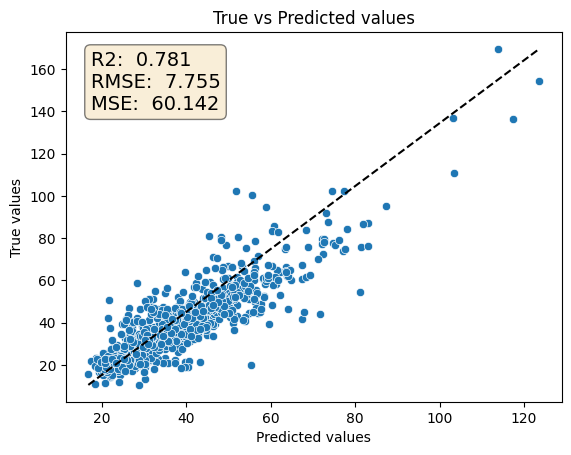

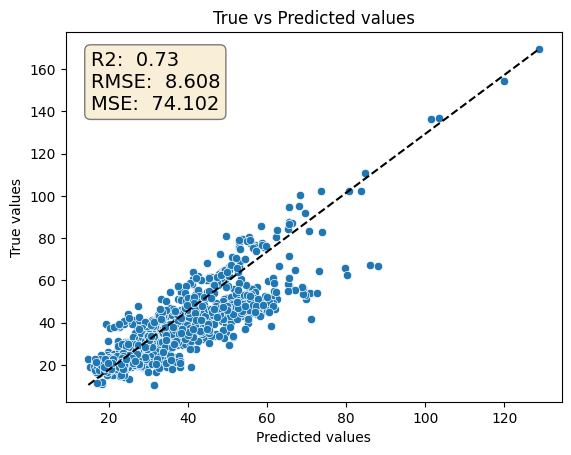

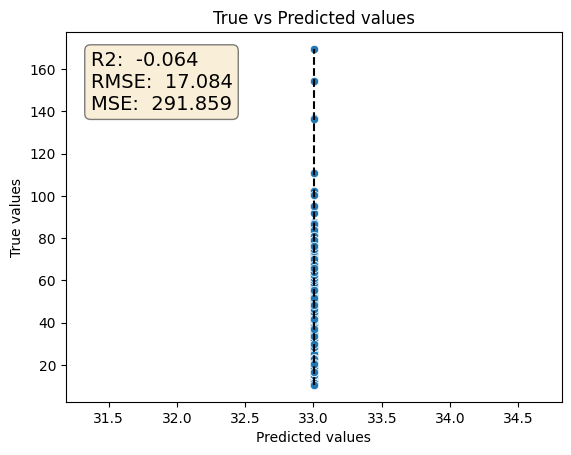

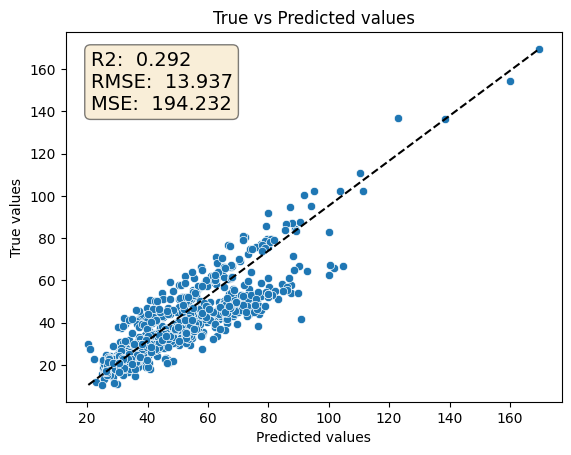

In [8]:
def lifesquare_knn_imputer(df):
    X = df.copy()
    X = X[(X['LifeSquare'] < 200) & (X['LifeSquare'] > 10)]
    X = X.drop(columns=['Healthcare_1', 'Price'])
    X = pd.get_dummies(X, drop_first=True)
    y = X['LifeSquare']
    X = X.drop(columns=['LifeSquare'])
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.15)
    scaler = RobustScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    knn_imputer = KNeighborsRegressor(n_neighbors=4, metric='minkowski')
    knn_imputer.fit(X_train, y_train)
    y_pred = knn_imputer.predict(X_test)
    y_pred_train = knn_imputer.predict(X_train)
    #evaluate_preds(y_train, y_pred_train)
    evaluate_preds(y_test, y_pred)
    return knn_imputer, X.columns.to_list(), scaler

def lin_imputer(df):
    X = df.copy()
    X = X[(X['LifeSquare'] < 200) & (X['LifeSquare'] > 10)]
    X = X.drop(columns=['Healthcare_1', 'Price'])
    X = pd.get_dummies(X, drop_first=True)
    y = X['LifeSquare']
    X = X.drop(columns=['LifeSquare'])
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.15)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    lin_imputer = LinearRegression()
    lin_imputer.fit(X_train, y_train)
    y_pred = lin_imputer.predict(X_test)
    y_pred_train = lin_imputer.predict(X_train)
    #evaluate_preds(y_train, y_pred_train)
    evaluate_preds(y_test, y_pred)

def median_imputer(df):
    X = df.copy()
    X = X[(X['LifeSquare'] < 200) & (X['LifeSquare'] > 10)]
    y = X['LifeSquare']
    X = X.drop(columns=['LifeSquare'])
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.15)
    median_inputer = y_train.median() * np.ones_like(y_test)
    evaluate_preds(y_test, median_inputer)

def logic_eq(df):
    X = df.copy()
    X = X[(X['LifeSquare'] < 200) & (X['LifeSquare'] > 10)]
    y = X['LifeSquare']
    X = X.drop(columns=['LifeSquare'])
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.15)
    y_pred = X_test['Square'] - X_test['KitchenSquare']
    evaluate_preds(y_test, y_pred)


knn_imputer, cols_for_knn, scaler = lifesquare_knn_imputer(df)
lin_imputer(df)
median_imputer(df)
logic_eq(df)


Из всех предложенных алгоритмов, лучше всего справляется метод ближайших соседей. В ходе опытов пришлось исключать некоторые аномальные значения из тренировочной выборки (`X['LifeSquare'] > 200)`) т.к они слишком сильно "перетягивают алгоритмы" в свою сторону. Заполним имеющиеся пропуски признака `LifeSquare`.

In [9]:
df = pd.get_dummies(df, drop_first=True, dtype=np.int8)
df_to_scale = df[cols_for_knn].copy()
scaled_df = scaler.transform(df_to_scale)

mask_na = df['LifeSquare'].isna()
df.loc[mask_na, 'LifeSquare'] = knn_imputer.predict(scaled_df[mask_na])


## Ниже не отмасштабировано, исправить

In [10]:
lifesquare_much_greater_square_mask = df['LifeSquare'] > (df['Square'] * 2)
df.loc[lifesquare_much_greater_square_mask, 'LifeSquare'] = knn_imputer.predict(df.loc[lifesquare_much_greater_square_mask, cols_for_knn])
lifesquare_greater_square_mask = df['LifeSquare'] > df['Square']
df.loc[lifesquare_greater_square_mask, ['LifeSquare', 'Square']] = df.loc[lifesquare_greater_square_mask, ['Square', 'LifeSquare']].values


c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but KNeighborsRegressor was fitted without feature names
  warnings.warn(


Рассмотрим признак `KitchenSquare`. В пресдтавленных данных он принимает значения от 0 до 2014. У 4 объектов `KitchenSquare` > `Square` и у 687 объектов `KitchenSquare + LifeSquare` > `Square`

Введем правила обработки:
1. Для объектов, у которых `KitchenSquare = 0` и `Rooms > 1` заменим медианой
2. Для объектов, у которых `KitchenSquare > Q_99` ограничим сверху Q_99

In [11]:
# KitchenSquare == 0 и Rooms > 1
kitchensquare_0_rooms_gt_1_mask = (df['KitchenSquare'] == 0) & (df['Rooms'] > 1)
df.loc[kitchensquare_0_rooms_gt_1_mask, 'KitchenSquare'] = df['KitchenSquare'].median()

# KitchenSquare > Q_99
kitchensquare_q99 = df['KitchenSquare'].quantile(0.99)
kitchensquare_greater_q99_mask = df['KitchenSquare'] > kitchensquare_q99
df.loc[kitchensquare_greater_q99_mask, 'KitchenSquare'] = kitchensquare_q99

Рассмотрим признак `HouseFloor`. Проблемы:
1. У 269 объектов `HouseFloor` = 0
2. У 3 объектов `HouseFloor` > 60 (`Floor` у этих объектов не превышает 10). Граница 60 выбрана на основе boxplot (`eda.ipynb`)

Правила Обработки:
1. Для помещений, у которых `HouseFloor = 0` заменим на `Floor`
2. Для помещений, у которых `HouseFloor > 60` заменим на `Floor`

In [12]:
housefloor_0_mask = (df['HouseFloor'] == 0)
housefloor_gt_60_mask = (df['HouseFloor'] > 60)
housefloor_0_or_gt_60_mask = housefloor_0_mask | housefloor_gt_60_mask
df.loc[housefloor_0_or_gt_60_mask, 'HouseFloor'] = df.loc[housefloor_0_or_gt_60_mask, 'Floor']

Рассмотрим признак `Floor`. Проблема: у 1556 объектов `Floor` > `HouseFloor`

Правило обработки:
`HouseFloor = Floor`

In [13]:
floor_gt_housefloor_mask = df['Floor'] > df['HouseFloor']
df.loc[floor_gt_housefloor_mask, 'HouseFloor'] = df.loc[floor_gt_housefloor_mask, 'Floor']

Рассмотрим признак `HouseYear`. У 2 объектов `HouseYear` > 2026.

Правило обработки: `HouseYear = 2026`

In [14]:
houseyear_gt_2026 = df['HouseYear'] > 2026
df.loc[houseyear_gt_2026, 'HouseYear'] = 2026

Рассмотрим признак `Healthcare_1`. Признак имеет большое количество пропусков. Попробуем заполнить их представленным выше набором методов

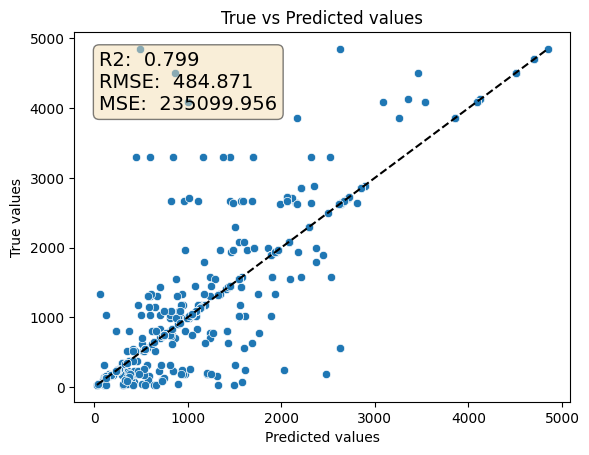

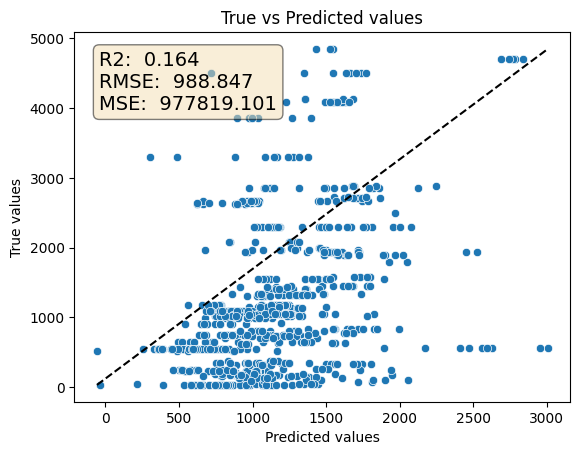

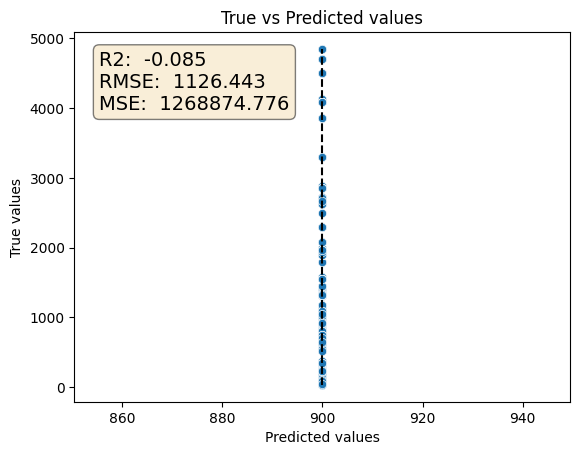

In [15]:
def healthcare_knn_imputer(df):
    X = df.copy()
    X = X.drop(columns=['Price'])
    X = pd.get_dummies(X, drop_first=True)
    X = X.dropna()
    y = X['Healthcare_1']
    X.drop('Healthcare_1', axis=1, inplace=True)
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.15)
    scaler = RobustScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    knn_imputer = KNeighborsRegressor(n_neighbors=4, metric='minkowski')
    knn_imputer.fit(X_train, y_train)
    y_pred = knn_imputer.predict(X_test)
    y_pred_train = knn_imputer.predict(X_train)
    #evaluate_preds(y_train, y_pred_train)
    evaluate_preds(y_test, y_pred)
    return knn_imputer, X.columns.to_list(), scaler

def healthcare_lin_imputer(df):
    X = df.copy()
    X = X.drop(columns=['Price'])
    X = pd.get_dummies(X, drop_first=True)
    X = X.dropna()
    y = X['Healthcare_1']
    X.drop('Healthcare_1', axis=1, inplace=True)
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.15)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    lin_imputer = LinearRegression()
    lin_imputer.fit(X_train, y_train)
    y_pred = lin_imputer.predict(X_test)
    y_pred_train = lin_imputer.predict(X_train)
    #evaluate_preds(y_train, y_pred_train)
    evaluate_preds(y_test, y_pred)

def healthcare_median_imputer(df):
    X = df.copy()
    X = X.dropna()
    y = X['Healthcare_1']
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.15)
    median_inputer = y_train.median() * np.ones_like(y_test)
    evaluate_preds(y_test, median_inputer)



imputer, cols_for_knn, scaler = healthcare_knn_imputer(df)
healthcare_lin_imputer(df)
healthcare_median_imputer(df)



Для заполнения пропусков опять воспользуемся `KNN`

In [18]:
healthcare_miss_mask = df['Healthcare_1'].isna()
healtcare_filled_mask = df['Healthcare_1'].notna()
X_to_scale_train = df.loc[healtcare_filled_mask, cols_for_knn]
y_train = df.loc[healtcare_filled_mask, 'Healthcare_1']
X_to_scale_test = df.loc[healthcare_miss_mask, cols_for_knn]
X_train_scaled = scaler.fit_transform(X_to_scale_train)
X_test_scaled = scaler.transform(X_to_scale_test)

imputer.fit(X_train_scaled, y_train)

df.loc[healthcare_miss_mask, 'Healthcare_1'] = imputer.predict(X_test_scaled)

In [19]:
df.head()

,Id,DistrictId,Rooms,Square,LifeSquare,KitchenSquare,Floor,HouseFloor,HouseYear,Ecology_1,Social_1,Social_2,Social_3,Healthcare_1,Helthcare_2,Shops_1,Price,Ecology_2_B,Ecology_3_B,Shops_2_B
0,11809,27,3.0,115.027311,84.791735,10.0,4,10.0,2014,0.075424,11,3097,0,575.25,0,0,305018.871089,1,1,1
1,3013,22,1.0,39.832524,23.169223,8.0,7,8.0,1966,0.118537,30,6207,1,1183.00,1,0,177734.553407,1,1,1
2,8215,1,3.0,78.342215,47.671972,10.0,2,17.0,1988,0.025609,33,5261,0,240.00,3,1,282078.720850,1,1,1
3,2352,1,1.0,43.798289,40.409907,1.0,10,22.0,1977,0.007122,1,264,0,540.00,0,1,168106.007630,1,1,1
4,13866,94,2.0,64.285067,38.562517,9.0,16,16.0,1972,0.282798,33,8667,2,840.00,0,6,343995.102962,1,1,1


Социальные и экологические показатели оставим без изменений. 

## Добавление новых признаков

Введем новые признаки:
1. Флаги `is_first_floor`, `is_last_floor`
2. `lifesquare_square_ratio = lifesquare / square`
3. `median_price_per_square` - средняя цена за кв.м по улице (в случае новой улицы - средняя цена за кв.м по всей обучающей выборке)
4. `floor_housefloor_ratio = floor / housefloor`
5. Флаг `is_studio` (`rooms = 1 & lifesquare > 0 & kitchensquare = 0`)
6. `median_price_per_room` - средняя цена за комнату по улице (в случае новой улицы - средняя цена за комнату по всей обучающей выборке)

In [22]:
is_first_floor_mask = (df['Floor'] == 1)
df['is_first_floor'] = is_first_floor_mask

is_last_floor_mask = (df['Floor'] == df['HouseFloor'])
df['is_last_floor'] = is_last_floor_mask

df['lifesquare_square_ratio'] = df['LifeSquare'] / df['Square']

df['floor_housefloor_ratio'] = df['Floor'] / df['HouseFloor']

is_studio_mask = (df['Rooms'] == 0) & (df['LifeSquare'] > 0) & (df['KitchenSquare'] == 0)
df['is_studio'] = is_studio_mask


temp = df[['DistrictId', 'Square']].copy()
temp['Price'] = df['Price'] 

# медианная цена квадратного метра по району
median_price_df = temp.groupby('DistrictId').apply(lambda g: g['Price'].median() / g['Square'].median()).rename('median_price_per_square').reset_index()

# общая медиана (на случай новых районов)
median_all_district = temp['Price'].median() / temp['Square'].median()


temp = df[['Rooms']].copy()
temp['Price'] = df['Price']

# медианная цена за комнату
median_price_df2 = (
        temp.groupby('Rooms')['Price'].median().rename('median_price_per_room').reset_index()
)
median_per_one_room = temp.loc[temp['Rooms'] == 1, 'Price'].median()

C:\Users\kstat\AppData\Local\Temp\ipykernel_27816\3260363285.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  median_price_df = temp.groupby('DistrictId').apply(lambda g: g['Price'].median() / g['Square'].median()).rename('median_price_per_square').reset_index()


## Опишем все преобразования

Финальная обработка будет выполняться в следующем порядке:
1. `KitchenSquare, LifeSquare = [0, 0] при Rooms = 0 & Square < Q_1`
2. `Square = Rooms * median_square_per_room при Q_1 < Rooms < Q_99 & Square < Q_1 + клип к Q_1square (median_per_room высчитывается на объектах, которые удовлетворяют условиям Q_1 < Rooms < Q_99 & Q_1 < Square < Q_99)`
3. Удаление объектов `Rooms = 0 & Square = 0 & LifeSquare = 0 & KitchenSquare = 0`
4. Для экстремально больших `Square` клип к верхней границе `Q_99 * 5`

5. Клип `Rooms` (`min=1, max=7`)
6. При малых отклонениях (`Lifesquare - Square < Square & LifeSquare - Square > 0`) меняем `Square` и `LifeSquare` местами
7. Заполнение пропусков `LifeSquare` при помощи KNN
8. Перезаполнение `LifeSquare` при помощи KNN (при `LifeSquare > Square * 2`)
9. повтор п.6
10. Замена `KitchenSquare` медианой при `Rooms > 1 & KitchenSquare = 0`
11. Клип `KitchenSquare` к Q_99 при `KitchenSquare > Q_99`
12. Замена `HouseFloor = Floor` при `HouseFloor = 0 | HouseFloor > 60`
13. Замена `HouseFloor = Floor` при `Floor > HouseFloor`
14. Замена `HouseYear = 2026` при `HouseYear > 2026`
15. Заполнение пропусков `Healthcare_1` при помощи KNN
16. Добавление признаков `is_first_floor`, `is_last_floor`, `lifesquare_square_ratio`, `media_price_per_square`, `floor_housefloor_ratio`, `is_studio`, `median_price_per_room`


Для контроля утечки признаков, оформим препроцессинг в виде трансформеров (см. `src/transformers.py`)